In [115]:
import pandas as pd 
import numpy as np

In [116]:
df=pd.read_csv("powerplant_data.csv")

In [117]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [118]:
# AT => Temperature
# V => Vaccum
# AP => Pressure
# RH => humidity

# PE => Produced Energy

In [119]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [120]:
X=df.drop("PE",axis=1)
y=df["PE"]

In [121]:
X

,AT,V,AP,RH
0,8.34,40.77,1010.84,90.01
1,23.64,58.49,1011.40,74.20
2,29.74,56.90,1007.15,41.91
3,19.07,49.69,1007.22,76.79
4,11.80,40.66,1017.13,97.20
...,...,...,...,...
9563,15.12,48.92,1011.80,72.93
9564,33.41,77.95,1010.30,59.72
9565,15.99,43.34,1014.20,78.66
9566,17.65,59.87,1018.58,94.65


In [122]:
y

0       480.48
1       445.75
2       438.76
3       453.09
4       464.43
         ...  
9563    462.59
9564    432.90
9565    465.96
9566    450.93
9567    451.67
Name: PE, Length: 9568, dtype: float64

In [123]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [124]:
df.shape

(9568, 5)

In [125]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [126]:
X_train_scaled

array([[ 0.74805289,  0.72006931, -0.32660017, -0.49711722],
       [ 0.86181948,  1.26515721, -0.98521113,  0.8181501 ],
       [ 0.93409473,  1.52314975,  0.32523844,  0.80167494],
       ...,
       [-0.22097078, -0.834965  ,  0.36756563, -0.83554456],
       [ 0.94747903,  1.14245344, -0.41971997, -0.45455637],
       [-1.77355014, -1.19049131,  1.92520594,  0.91837402]],
      shape=(7654, 4))

In [127]:
X_test_scaled

array([[ 1.34499288,  0.23869298, -1.28658067, -1.10532538],
       [ 0.81095912,  1.36269098, -0.74140656,  0.26485915],
       [-0.2437241 , -0.73900436,  1.99970178, -0.19713193],
       ...,
       [-0.67068342, -1.15902881, -0.29951077, -0.10651852],
       [ 1.31420898,  1.33752097, -0.87346737, -0.44288647],
       [-0.2611237 , -0.27021304,  0.37433797,  1.10646548]],
      shape=(1914, 4))

In [128]:
import torch
import torch.nn as nn 

In [129]:
X_train_tensor=torch.tensor(X_train_scaled,dtype=torch.float32)

y_train_tensor=torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)

In [130]:
X_test_tensor=torch.tensor(X_test_scaled,dtype=torch.float32)

y_test_tensor=torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)

In [131]:
from torch.utils.data import TensorDataset , DataLoader

In [132]:
train_dataset=TensorDataset(X_train_tensor,y_train_tensor)

In [133]:
test_dataset=TensorDataset(X_test_tensor,y_test_tensor)

In [134]:
train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)

In [135]:
test_loader=DataLoader(test_dataset,batch_size=32)

### Define ANN model

In [136]:
class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()

        self.model=nn.Sequential(
            # 1st hidden layer
            nn.Linear(X_train.shape[1],6),
            nn.ReLU(),

            # 2nd hidden layer
            nn.Linear(6,6),
            nn.ReLU(),

            # output layer
            nn.Linear(6,1)
        )

    def forward(self,x):
        return self.model(x)

    # Pytorch automatically handles backpropogation


In [137]:
model=ANN()

In [138]:
import torch.optim as optim

In [139]:
# Loss
crieterion=nn.MSELoss()

In [140]:
# Optimizer
optimizer=optim.Adam(model.parameters())

### Train the epochs

In [141]:
epochs=100
train_losses=[]
valid_losses=[]

best_val_loss=float("inf")

for epoch in range(epochs):
    model.train() # Training mode 

    running_loss=0.0

    for xb,yb in train_loader: # xb=> feature of one batch and yb => label of one batch

        optimizer.zero_grad()

        outputs=model(xb) # Forward prop... Calculate outputs
        loss=crieterion(outputs,yb) # Calculate loss
        loss.backward() # Back prop .. calculate gradient
        optimizer.step()  # update params

        running_loss+=loss.item() # tensor to float value

    epoch_training_loss=running_loss/len(train_loader)

    train_losses.append(epoch_training_loss)

    # Validation
    running_val_losses=0.0

    model.eval()
    with torch.no_grad():
        for xb,yb in test_loader:
            outputs=model(xb)
            loss=crieterion(outputs,yb)
            running_val_losses+=loss.item()

    epoch_val_loss=running_val_losses/len(test_loader)
    valid_losses.append(epoch_val_loss)

    print(f"For {epoch+1}/{epochs} => training loss = {epoch_training_loss} & validation loss = {epoch_val_loss}")

    if epoch_val_loss<best_val_loss:
        best_val_loss=epoch_val_loss
        torch.save(model.state_dict(),"perfect_model.pt")

For 1/100 => training loss = 206459.69140625 & validation loss = 206148.80052083332
For 2/100 => training loss = 205916.23059895833 & validation loss = 204637.9046875
For 3/100 => training loss = 200844.57936197918 & validation loss = 194816.3046875
For 4/100 => training loss = 184737.98821614584 & validation loss = 172902.72239583332
For 5/100 => training loss = 157695.33600260416 & validation loss = 142168.10677083334
For 6/100 => training loss = 125043.47027994791 & validation loss = 109046.77955729167
For 7/100 => training loss = 92112.50514322917 & validation loss = 77237.10950520834
For 8/100 => training loss = 64269.90960286458 & validation loss = 53908.770182291664
For 9/100 => training loss = 45265.06655273437 & validation loss = 38650.34361979167
For 10/100 => training loss = 33033.06977539063 & validation loss = 28600.730631510418
For 11/100 => training loss = 25026.74472249349 & validation loss = 21942.59541015625
For 12/100 => training loss = 19631.232975260416 & validatio

In [142]:
import matplotlib.pyplot as plt 

df=pd.DataFrame({
    "train_losses":train_losses,
    "val_losses":valid_losses
})


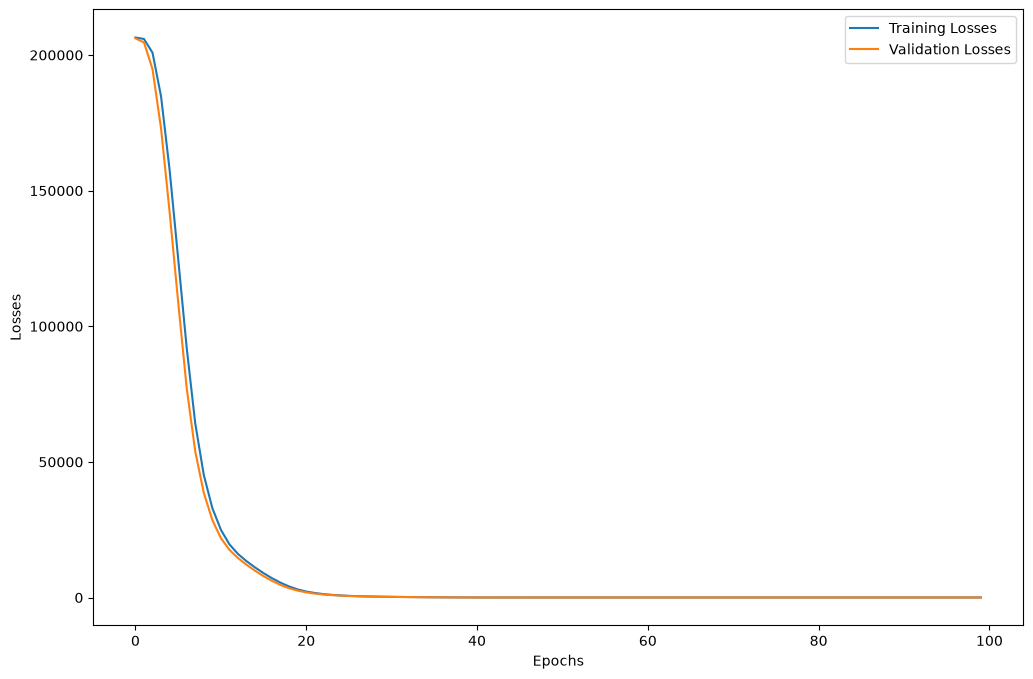

In [143]:
plt.figure(figsize=(12,8))
plt.plot(df["train_losses"],label="Training Losses")
plt.plot(df["val_losses"],label="Validation Losses")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()
plt.show()

In [144]:
# Load the best model 

model.load_state_dict(torch.load("perfect_model.pt"))

<All keys matched successfully>

In [145]:
# Evaluate our model

model.eval()

with torch.no_grad():
    train_preds=model(X_train_tensor)
    test_preds=model(X_test_tensor)

    train_mse_loss=crieterion(train_preds,y_train_tensor)
    test_mse_loss=crieterion(test_preds,y_test_tensor)


print(f"Training MSE: {train_mse_loss.item()}")
print(f"Testing MSE: {test_mse_loss.item()}")

Training MSE: 21.137800216674805
Testing MSE: 19.669797897338867


In [146]:
from sklearn.metrics import r2_score

print("R2 score:",r2_score(y_test,test_preds))

R2 score: 0.9312591349497494


In [147]:
predicted_df=pd.DataFrame(test_preds.numpy(),columns=["Predicted Values"])
actual_df=pd.DataFrame(y_test.values,columns=["Actual Values"])

In [148]:
pd.concat([predicted_df,actual_df],axis=1)

,Predicted Values,Actual Values
0,435.549744,433.27
1,437.246643,438.16
2,461.280884,458.42
3,476.126801,480.82
4,435.675110,441.41
...,...,...
1909,451.405579,456.70
1910,431.958405,438.04
1911,467.614960,467.80
1912,431.435394,437.14
